# 3

## (a)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=0)
p, sigma = 1000, 1.0
n_values = np.array([50, 100, 200, 400, 800, 1600])
trials = 100
results = []

for n in n_values:
    measurements = []
    for _ in range(trials):
        X = rng.normal(0, 1, size=(n, p))
        epsilon = rng.normal(0, sigma, size=n)
        measurements.append(np.max(np.abs(X.T @ epsilon / n)))
    measurements = np.array(measurements)
    lam0 = sigma * np.sqrt(2 * np.log(p) / n)
    results.append((n, measurements.mean(), measurements.std(ddof=1),
                    measurements.std(ddof=1) / np.sqrt(trials), lam0,
                    measurements.mean() / lam0))

results = np.array(results)
slope = np.polyfit(np.log(results[:, 0]), np.log(results[:, 1]), 1)[0]
results, slope

(array([[5.00000000e+01, 4.88022862e-01, 6.42583230e-02, 6.42583230e-03,
         5.25652177e-01, 9.28414042e-01],
        [1.00000000e+02, 3.43539483e-01, 3.68017559e-02, 3.68017559e-03,
         3.71692219e-01, 9.24257935e-01],
        [2.00000000e+02, 2.43493566e-01, 2.70290778e-02, 2.70290778e-03,
         2.62826088e-01, 9.26443671e-01],
        [4.00000000e+02, 1.73718932e-01, 1.70579842e-02, 1.70579842e-03,
         1.85846109e-01, 9.34746132e-01],
        [8.00000000e+02, 1.21766597e-01, 1.32863779e-02, 1.32863779e-03,
         1.31413044e-01, 9.26594443e-01],
        [1.60000000e+03, 8.64825114e-02, 8.51083136e-03, 8.51083136e-04,
         9.29230547e-02, 9.30689500e-01]]),
 np.float64(-0.4988155200940045))

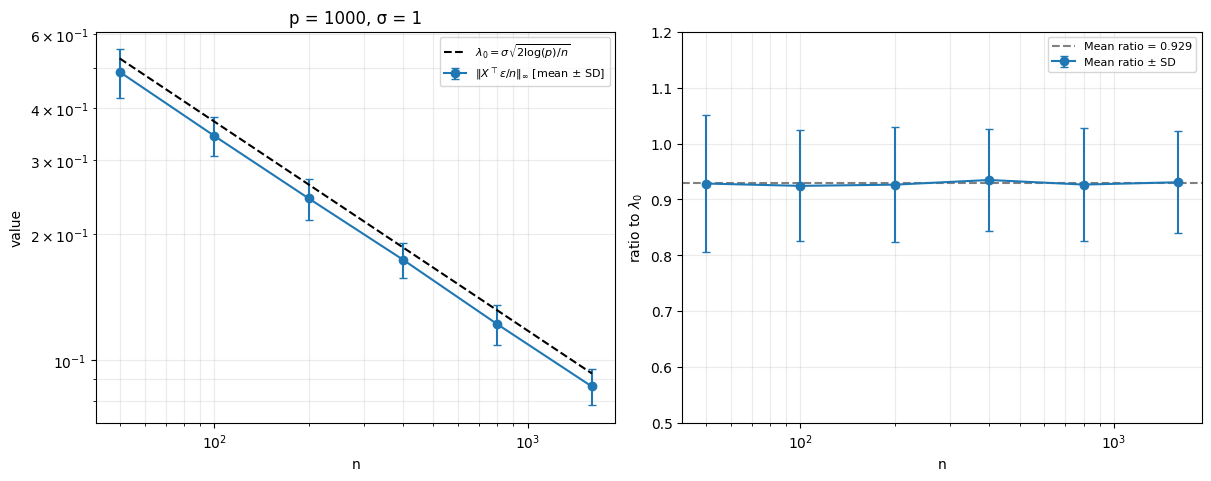

In [5]:
from matplotlib.ticker import ScalarFormatter

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), layout="constrained")
n, avg, sd, se, lam, ratio = results.T

axes[0].errorbar(n, avg, yerr=sd, fmt="o-", capsize=3, label=r"$\|X^\top\varepsilon/n\|_\infty$ [mean $\pm$ SD]")
axes[0].plot(n, lam, "k--", label=r"$\lambda_0=\sigma\sqrt{2\log(p)/n}$")
axes[0].set(xscale="log", yscale="log", xlabel="n",
            ylabel="value", title="p = 1000, σ = 1")
axes[0].grid(True, which="both", alpha=.25)
axes[0].legend(fontsize=8)

axes[1].errorbar(n, ratio, yerr=sd / lam, fmt="o-", capsize=3, label="Mean ratio ± SD")
axes[1].axhline(np.mean(ratio), linestyle="--", color="gray", label=f"Mean ratio = {np.mean(ratio):.3f}")
axes[1].set(xscale="log", xlabel="n", ylabel=r"ratio to $\lambda_0$")
axes[1].set_ylim(.5, 1.2)
axes[1].grid(True, which="both", alpha=.25)
axes[1].legend(fontsize=8)

plt.show()

The fitted slope of the log-log plot is roughly $-0.5$. The ratio hovers around 
a constant $0.92$. From lecture 7, the union bound over Gaussian tails shows that:
$$
    \left\|\frac{1}{n}\epsilon^\top X\right\|_\infty \leq C\sigma \sqrt{\frac{\log p}n}
$$
for some constant $C > 0$, and then chooses $\lambda = 2C\sigma\sqrt{\frac{\log p}{n}}$.
This shows that noise level scales as
$$
    \left\|\frac{1}{n}\epsilon^\top X\right\|_\infty = O_p\left(\sigma \sqrt{\frac{\log p}n}\right)
$$.
We have $\lambda_0 = \sigma \sqrt{\frac{2\log p}{n}}$. Both expressions have the
same dependence on $n$ and $p$. Since $p = 1000$, $\sigma = 1$ are fixed, both
scale to $n^{-1/2}$. This explains why the experimentally observed ratio remains
approximately constant at around $0.92$ while $n$ increases. The constant $\sqrt{2}$
in $\lambda_0$ is asymptotically sharp for the maximum of independent Gaussian
variables, but is slightly conservative for finite $p$. Our observed ratio indicates
that $\lambda_0$ slightly overestimates the expected noise level when $p = 1000$.

## (b)

In [12]:
from scipy.optimize import linprog
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits

rng = np.random.default_rng(seed=0)
T = 20
p, sigma = 256, 0
n_values = np.arange(8, 257, 8)
k_values = np.arange(1, 64, 2)

In [ ]:
# default data generation 

success = np.zeros((len(n_values), len(k_values)), dtype=float)
for i, n in enumerate(n_values):
    for j, k in enumerate(k_values):
        for trial in range(T):
            X = rng.standard_normal((n, p))
            beta = np.zeros(p)
            support = rng.choice(p, size=k, replace=False)
            beta[support] = rng.choice([-1.0, 1.0], size=k)
            y = X @ beta
            # beta = beta_plus - beta_minus, beta_plus, beta_minus >= 0
            # Objective min 1^T beta_plus + 1^T beta_minus, subject to X beta = y
            fit = linprog(np.ones(2*p), A_eq=np.concatenate([X, -X], axis=1),
                          b_eq=y, bounds=(0, None), method='highs')
            if fit.success:
                beta_hat = fit.x[:p] - fit.x[p:]
                if np.linalg.norm(beta_hat-beta) <= 1e-4*np.linalg.norm(beta):
                    success[i,j] += 1

In [ ]:
# parallelized

# Run all T trials for one (n, k) configuration
def run_config(i, j, n, k, seed):
    rng = np.random.default_rng(seed)
    successes = 0

    with threadpool_limits(limits=1):
        for trial in range(T):
            X = rng.standard_normal((n, p))
            beta = np.zeros(p)
            support = rng.choice(p, size=k, replace=False)
            beta[support] = rng.choice([-1.0, 1.0], size=k)
            y = X @ beta

            # beta = beta_plus - beta_minus
            # Objective: min 1^T beta_plus + 1^T beta_minus
            # Subject to: X beta = y
            fit = linprog(
                np.ones(2 * p),
                A_eq=np.concatenate([X, -X], axis=1),
                b_eq=y,
                bounds=(0, None),
                method="highs",
            )

            if fit.success:
                beta_hat = fit.x[:p] - fit.x[p:]

                if np.linalg.norm(beta_hat - beta) <= 1e-4 * np.linalg.norm(beta):
                    successes += 1

    return i, j, successes / T

rng = np.random.SeedSequence(0)
seeds = rng.spawn(len(n_values) * len(k_values))

n_jobs = 8

# Parallelize across (n, k) configurations
results = Parallel(
    n_jobs=n_jobs,
    backend="loky",
    verbose=10
)(
    delayed(run_config)(i, j, n, k, seeds[i * len(k_values) + j])
    for i, n in enumerate(n_values)
    for j, k in enumerate(k_values)
)

# Reconstruct success probability matrix
success = np.zeros((len(n_values), len(k_values)))

for i, j, rate in results:
    success[i, j] = rate

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    1.2s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:    1.3s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:    1.3s
[Parallel(n_jobs=8)]: Done  25 tasks      | elapsed:    1.5s
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    1.6s
[Parallel(n_jobs=8)]: Done  45 tasks      | elapsed:    1.8s
[Parallel(n_jobs=8)]: Done  56 tasks      | elapsed:    1.9s
[Parallel(n_jobs=8)]: Done  69 tasks      | elapsed:    2.2s
[Parallel(n_jobs=8)]: Done  82 tasks      | elapsed:    2.6s
[Parallel(n_jobs=8)]: Done  97 tasks      | elapsed:    3.0s
[Parallel(n_jobs=8)]: Done 112 tasks      | elapsed:    3.3s
[Parallel(n_jobs=8)]: Done 129 tasks      | elapsed:    3.8s
[Parallel(n_jobs=8)]: Done 146 tasks      | elapsed:    4.4s
[Parallel(n_jobs=8)]: Done 165 tasks      | elapsed:    5.1s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    5.9s
[Parallel(

In [17]:
np.save("success.npy", success)

C: 1.010011803526003
n50: [(np.int64(1), np.int64(8)), (np.int64(3), np.int64(24)), (np.int64(5), np.int64(32)), (np.int64(7), np.int64(32)), (np.int64(9), np.int64(40)), (np.int64(11), np.int64(48)), (np.int64(13), np.int64(56)), (np.int64(15), np.int64(56)), (np.int64(17), np.int64(64)), (np.int64(19), np.int64(72)), (np.int64(21), np.int64(80)), (np.int64(23), np.int64(80)), (np.int64(25), np.int64(80)), (np.int64(27), np.int64(88)), (np.int64(29), np.int64(96)), (np.int64(31), np.int64(96)), (np.int64(33), np.int64(104)), (np.int64(35), np.int64(112)), (np.int64(37), np.int64(112)), (np.int64(39), np.int64(112)), (np.int64(41), np.int64(120)), (np.int64(43), np.int64(120)), (np.int64(45), np.int64(120)), (np.int64(47), np.int64(128)), (np.int64(49), np.int64(128)), (np.int64(51), np.int64(136)), (np.int64(53), np.int64(144)), (np.int64(55), np.int64(136)), (np.int64(57), np.int64(144)), (np.int64(59), np.int64(144)), (np.int64(61), np.int64(144)), (np.int64(63), np.int64(152))]


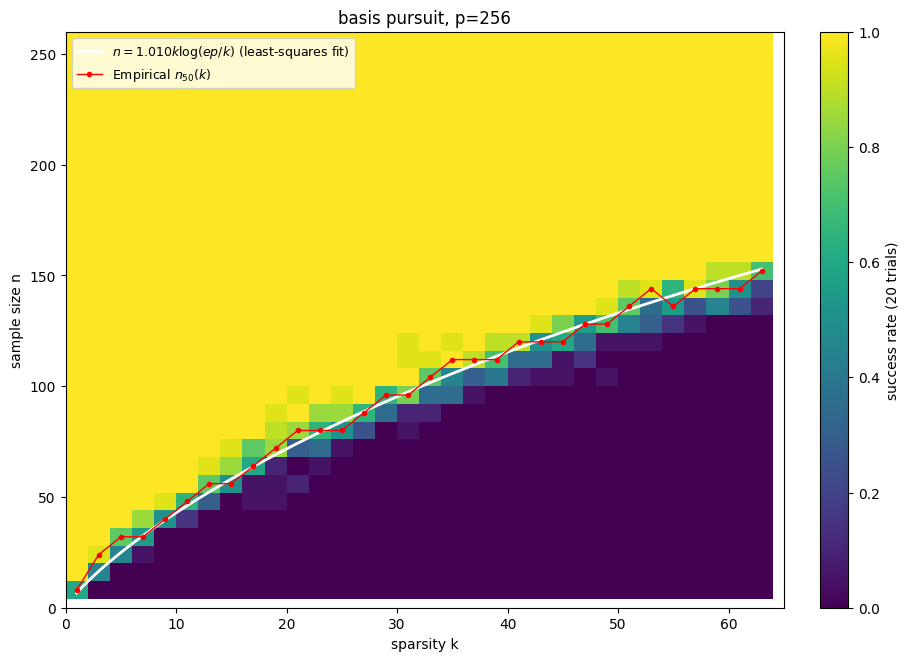

In [19]:
n50 = np.array([n_values[np.where(success[:,j] >= 0.5)[0][0]] if np.any(success[:,j]>=0.5)
                else np.nan for j in range(len(k_values))])
factor = k_values * np.log(np.e * p / k_values)
valid = np.isfinite(n50)
C = np.sum(factor[valid]*n50[valid]) / np.sum(factor[valid]**2)

fig, ax = plt.subplots(figsize=(9,6.5), layout='constrained')
k_edges = np.r_[k_values[0] - (k_values[1] - k_values[0]) / 2, (k_values[:-1] + k_values[1:]) / 2,
                k_values[-1] + (k_values[-1] - k_values[-2]) / 2]
n_edges = np.r_[n_values[0] - (n_values[1] - n_values[0]) / 2, (n_values[:-1] + n_values[1:]) / 2,
                n_values[-1] + (n_values[-1] - n_values[-2]) / 2]
heat = ax.pcolormesh(k_edges, n_edges, success, vmin=0, vmax=1, cmap='viridis', shading='flat')
k_dense = np.linspace(1, 63, 400)
ax.plot(k_dense, C * k_dense * np.log(np.e * p / k_dense), color='white', lw=2,
        label=rf'$n = {C:.3f} k\log(ep/k)$ (least-squares fit)')
ax.plot(k_values[valid], n50[valid], color='red', marker='o', lw=1, markersize=3,
        label=r'Empirical $n_{50}(k)$')
ax.set(xlabel='sparsity k', ylabel='sample size n', title='basis pursuit, p=256')
ax.set_xlim(0, 65)
ax.set_ylim(0, 260)
ax.legend(loc='upper left', fontsize=9)
cbar = fig.colorbar(heat, ax=ax)
cbar.set_label(f'success rate ({T} trials)')
print('C:',C)
print('n50:',list(zip(k_values,n50)))

The shape of the empirical boundary (red dotted lines) follows $k \log(e/k)$, $C = 1.01$.